# H&M Customer Segmentation — Phase 1: Dataset Audit

**Mục tiêu của Phase 1:** chưa làm sạch dữ liệu, chưa tạo cluster, chưa chọn feature cuối.

Notebook này chỉ trả lời 6 câu hỏi:

1. Ba file H&M thực sự có những cột nào?
2. Quy mô, thời gian quan sát và độ phủ customer/product ra sao?
3. Missing, duplicate và cardinality của metadata thế nào?
4. Hành vi mua lặp lại có đủ để xây `Frequency`, `Interpurchase Time` và `Purchase Regularity` không?
5. Candidate feature nào **thực sự tính được** từ H&M?
6. Những vấn đề dữ liệu nào cần chuyển sang Phase 2 — Cleaning Decisions?

Nguồn dữ liệu chính: Kaggle — **H&M Personalized Fashion Recommendations**.

> Quy tắc nghiên cứu: từ Phase 1 trở đi, mọi thí nghiệm chính dùng cùng một snapshot của `transactions_train.csv`, `customers.csv`, `articles.csv`.

## 0. Cấu trúc thư mục

Đặt ba CSV vào:

```text
project/
├── data/
│   └── raw/
│       ├── transactions_train.csv
│       ├── customers.csv
│       └── articles.csv
├── notebooks/
│   └── Customer_Segmentation_HM_Phase1_Audit.ipynb
└── reports/
    ├── figures/
    │   └── phase1_audit/
    └── tables/
        └── phase1_audit/
```

Không cần tải thư mục ảnh cho bài toán segmentation hiện tại.

In [1]:
from pathlib import Path
from collections import Counter
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# Nếu notebook nằm trong thư mục notebooks/, dùng PROJECT_ROOT = Path("..")
# Nếu notebook nằm ngay thư mục project/, đổi thành Path(".")
PROJECT_ROOT = Path("..")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "reports" / "figures" / "phase1_audit"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables" / "phase1_audit"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

TRANSACTIONS_PATH = RAW_DIR / "transactions_train.csv"
CUSTOMERS_PATH = RAW_DIR / "customers.csv"
ARTICLES_PATH = RAW_DIR / "articles.csv"

required_files = [TRANSACTIONS_PATH, CUSTOMERS_PATH, ARTICLES_PATH]
for p in required_files:
    print(f"{p}: {'OK' if p.exists() else 'MISSING'}")

..\data\raw\transactions_train.csv: OK
..\data\raw\customers.csv: OK
..\data\raw\articles.csv: OK


## 1. Data dictionary ban đầu

Ta **không suy diễn thêm thông tin chưa có trong dữ liệu**.

- `transactions_train.csv`: purchase date, customer, article, price, sales channel.
- `customers.csv`: customer metadata.
- `articles.csv`: fashion-product metadata.

Đặc biệt: transaction data **không có `order_id`**. Vì vậy sau này `Frequency` cần được định nghĩa và kiểm chứng cẩn thận, ví dụ `distinct purchase days`, thay vì gọi mỗi dòng là một order.

In [2]:
# Chỉ chạy khi cả ba file đã có.
customers = pd.read_csv(
    CUSTOMERS_PATH,
    dtype={"customer_id": "string"}
)
articles = pd.read_csv(
    ARTICLES_PATH,
    dtype={"article_id": "string"}
)

# Đọc sample nhỏ của transactions để audit schema mà không tốn RAM.
transactions_sample = pd.read_csv(
    TRANSACTIONS_PATH,
    nrows=200_000,
    dtype={
        "customer_id": "string",
        "article_id": "string",
        "sales_channel_id": "Int8"
    }
)
transactions_sample["t_dat"] = pd.to_datetime(transactions_sample["t_dat"], errors="coerce")

print("customers:", customers.shape)
print("articles:", articles.shape)
print("transaction sample:", transactions_sample.shape)

display(customers.head())
display(articles.head())
display(transactions_sample.head())

customers: (1371980, 7)
articles: (105542, 25)
transaction sample: (200000, 5)


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687004,0.016932,2


In [3]:
def schema_table(df, dataset_name):
    return pd.DataFrame({
        "dataset": dataset_name,
        "column": df.columns,
        "dtype": [str(x) for x in df.dtypes],
        "missing_count": df.isna().sum().values,
        "missing_pct": (df.isna().mean().values * 100).round(4),
        "n_unique": [df[c].nunique(dropna=True) for c in df.columns]
    })

schema_customers = schema_table(customers, "customers")
schema_articles = schema_table(articles, "articles")
schema_tx_sample = schema_table(transactions_sample, "transactions_sample")

schema_all = pd.concat(
    [schema_customers, schema_articles, schema_tx_sample],
    ignore_index=True
)

display(schema_all)
schema_all.to_csv(TABLE_DIR / "01_schema_and_missing_overview.csv", index=False)

,dataset,column,dtype,missing_count,missing_pct,n_unique
0,customers,customer_id,string,0,0.0000,1371980
1,customers,FN,float64,895050,65.2378,1
2,customers,Active,float64,907576,66.1508,1
3,customers,club_member_status,str,6062,0.4418,3
4,customers,fashion_news_frequency,str,16011,1.1670,3
5,customers,age,float64,15861,1.1561,84
6,customers,postal_code,str,0,0.0000,352899
7,articles,article_id,string,0,0.0000,105542
8,articles,product_code,int64,0,0.0000,47224
9,articles,prod_name,str,0,0.0000,45875


## 2. Audit `customers.csv`

Mục đích:

- `customer_id` có duy nhất không?
- `age`, `FN`, `Active`, membership/news metadata thiếu bao nhiêu?
- Các biến categorical có những giá trị nào?
- Có tuổi bất thường cần chuyển sang Phase 2 không?

**Chưa xóa hay điền missing ở bước này.**

In [4]:
customer_audit = pd.DataFrame({
    "metric": [
        "rows",
        "unique_customer_id",
        "duplicate_customer_id",
        "missing_customer_id"
    ],
    "value": [
        len(customers),
        customers["customer_id"].nunique(dropna=True),
        customers["customer_id"].duplicated().sum(),
        customers["customer_id"].isna().sum()
    ]
})

display(customer_audit)
customer_audit.to_csv(TABLE_DIR / "02_customer_audit_summary.csv", index=False)

# Cell tạo customer_missing (sửa lại cho chắc chắn tên cột)
missing_series = customers.isna().mean().mul(100).sort_values(ascending=False)

customer_missing = pd.DataFrame({
    "feature": missing_series.index,
    "missing_pct": missing_series.values
})

display(customer_missing)
customer_missing.to_csv(TABLE_DIR / "03_customer_missing.csv", index=False)

,metric,value
0,rows,1371980
1,unique_customer_id,1371980
2,duplicate_customer_id,0
3,missing_customer_id,0


,feature,missing_pct
0,Active,66.150819
1,FN,65.237831
2,fashion_news_frequency,1.167000
3,age,1.156066
4,club_member_status,0.441843
5,customer_id,0.000000
6,postal_code,0.000000


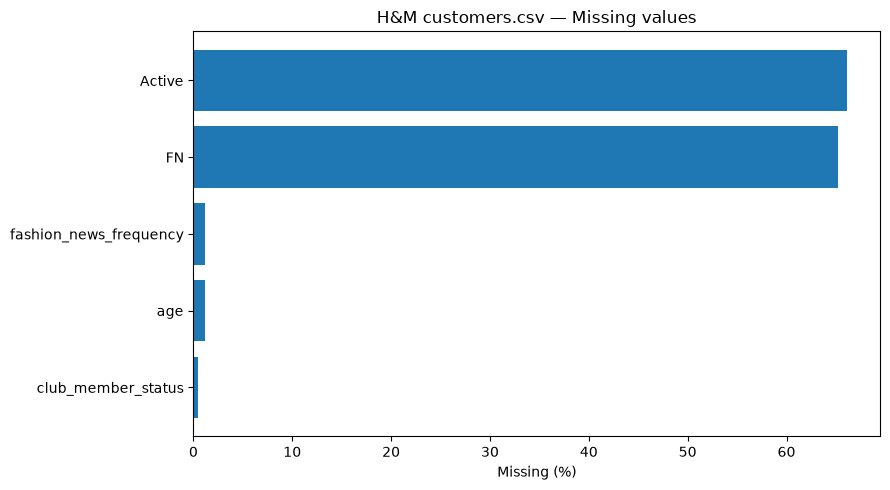

In [5]:
# Biểu đồ missing của customer metadata
plot_df = customer_missing[customer_missing["missing_pct"] > 0].copy()

if not plot_df.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(plot_df["feature"], plot_df["missing_pct"])
    ax.set_xlabel("Missing (%)")
    ax.set_title("H&M customers.csv — Missing values")
    ax.invert_yaxis()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "01_customers_missing.png", dpi=160, bbox_inches="tight")
    plt.show()


--- FN ---


,FN,count
0,NaN,895050
1,1.0,476930



--- Active ---


,Active,count
0,NaN,907576
1,1.0,464404



--- club_member_status ---


,club_member_status,count
0,ACTIVE,1272491
1,PRE-CREATE,92960
2,NaN,6062
3,LEFT CLUB,467



--- fashion_news_frequency ---


,fashion_news_frequency,count
0,NONE,877711
1,Regularly,477416
2,NaN,16011
3,Monthly,842


count    1.356119e+06
mean     3.638696e+01
std      1.431363e+01
min      1.600000e+01
1%       1.800000e+01
5%       1.900000e+01
25%      2.400000e+01
50%      3.200000e+01
75%      4.900000e+01
95%      6.200000e+01
99%      7.100000e+01
max      9.900000e+01
Name: age, dtype: float64

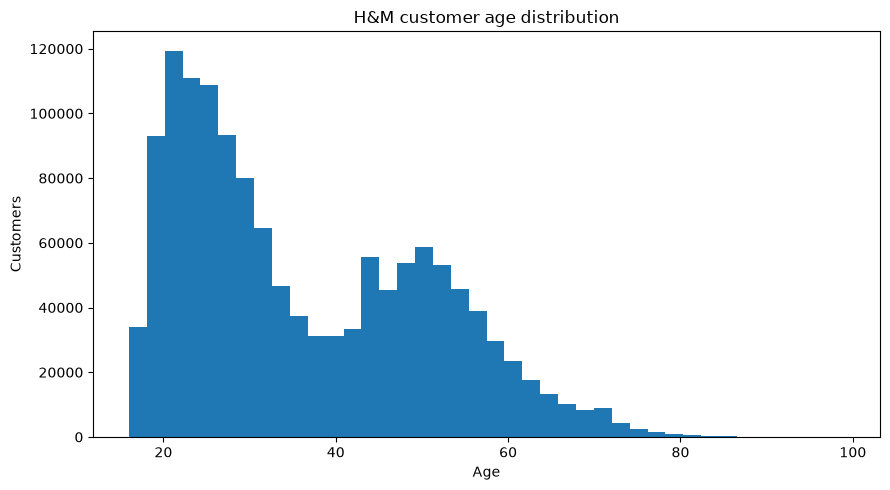

In [6]:
# Kiểm tra metadata categorical; chỉ quan sát, chưa encode.
categorical_customer_cols = [
    c for c in ["FN", "Active", "club_member_status", "fashion_news_frequency"]
    if c in customers.columns
]

for c in categorical_customer_cols:
    print(f"\n--- {c} ---")
    display(
        customers[c]
        .value_counts(dropna=False)
        .rename_axis(c)
        .reset_index(name="count")
    )

if "age" in customers.columns:
    display(customers["age"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

    age_non_null = customers["age"].dropna()
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(age_non_null, bins=40)
    ax.set_xlabel("Age")
    ax.set_ylabel("Customers")
    ax.set_title("H&M customer age distribution")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "02_customer_age_distribution.png", dpi=160, bbox_inches="tight")
    plt.show()

## 3. Audit `articles.csv`

Mục đích:

- `article_id` có duy nhất không?
- Metadata fashion nào có coverage tốt?
- `product_type`, `department`, `section`, `garment_group`, `colour` có cardinality bao nhiêu?
- Candidate diversity feature nào có cơ sở dữ liệu thật?

In [7]:
article_audit = pd.DataFrame({
    "metric": [
        "rows",
        "unique_article_id",
        "duplicate_article_id",
        "missing_article_id"
    ],
    "value": [
        len(articles),
        articles["article_id"].nunique(dropna=True),
        articles["article_id"].duplicated().sum(),
        articles["article_id"].isna().sum()
    ]
})

display(article_audit)
article_audit.to_csv(TABLE_DIR / "04_article_audit_summary.csv", index=False)

article_missing = (
    articles.isna().mean().mul(100)
    .sort_values(ascending=False)
    .rename("missing_pct")
    .reset_index(name="feature")
)
display(article_missing.head(20))
article_missing.to_csv(TABLE_DIR / "05_article_missing.csv", index=False)

,metric,value
0,rows,105542
1,unique_article_id,105542
2,duplicate_article_id,0
3,missing_article_id,0


,index,feature
0,detail_desc,0.394156
1,product_code,0.000000
2,prod_name,0.000000
3,product_type_no,0.000000
4,product_type_name,0.000000
5,product_group_name,0.000000
6,graphical_appearance_no,0.000000
7,graphical_appearance_name,0.000000
8,article_id,0.000000
9,colour_group_code,0.000000


,feature,n_unique,missing_pct
3,department_name,250,0.0
0,product_type_name,131,0.0
6,section_name,56,0.0
2,colour_group_name,50,0.0
7,garment_group_name,21,0.0
1,product_group_name,19,0.0
4,index_name,10,0.0
5,index_group_name,5,0.0


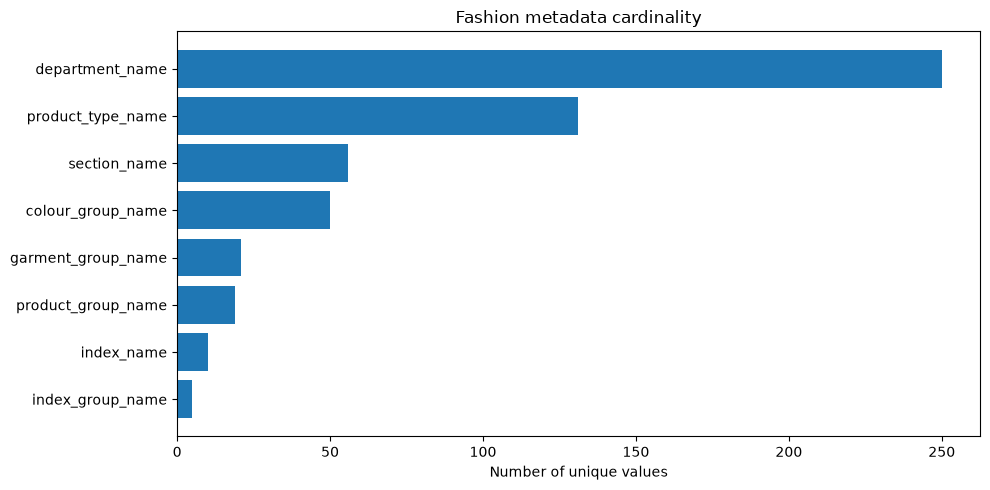

In [8]:
fashion_cols = [
    "product_type_name",
    "product_group_name",
    "colour_group_name",
    "department_name",
    "index_name",
    "index_group_name",
    "section_name",
    "garment_group_name"
]
fashion_cols = [c for c in fashion_cols if c in articles.columns]

cardinality = pd.DataFrame({
    "feature": fashion_cols,
    "n_unique": [articles[c].nunique(dropna=True) for c in fashion_cols],
    "missing_pct": [articles[c].isna().mean() * 100 for c in fashion_cols]
}).sort_values("n_unique", ascending=False)

display(cardinality)
cardinality.to_csv(TABLE_DIR / "06_fashion_metadata_cardinality.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(cardinality["feature"], cardinality["n_unique"])
ax.set_xlabel("Number of unique values")
ax.set_title("Fashion metadata cardinality")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_fashion_metadata_cardinality.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Full scan `transactions_train.csv` an toàn bộ nhớ

File transactions rất lớn, vì vậy cell dưới đây dùng `chunksize`.

Ta thu thập:

- tổng số dòng;
- khoảng thời gian;
- missing;
- số customer/article;
- sales-channel counts;
- price min/max/mean;
- số transaction rows theo customer;
- sample giá để vẽ distribution.

> `transaction_rows_per_customer` **không đồng nghĩa với number of orders**. Nó chỉ là audit ban đầu về mức độ lặp lại.

In [9]:
CHUNK_SIZE = 1_000_000

row_count = 0
missing_counts = Counter()
channel_counts = Counter()
customer_line_counts = Counter()

unique_customers = set()
unique_articles = set()

min_date = None
max_date = None

price_sum = 0.0
price_count = 0
price_min = math.inf
price_max = -math.inf

price_samples = []

usecols = ["t_dat", "customer_id", "article_id", "price", "sales_channel_id"]

for i, chunk in enumerate(pd.read_csv(
    TRANSACTIONS_PATH,
    usecols=usecols,
    chunksize=CHUNK_SIZE,
    dtype={
        "customer_id": "string",
        "article_id": "string",
        "sales_channel_id": "Int8"
    }
)):
    chunk["t_dat"] = pd.to_datetime(chunk["t_dat"], errors="coerce")

    row_count += len(chunk)

    for col, n in chunk.isna().sum().items():
        missing_counts[col] += int(n)

    unique_customers.update(chunk["customer_id"].dropna().unique().tolist())
    unique_articles.update(chunk["article_id"].dropna().unique().tolist())

    channel_counts.update(
        chunk["sales_channel_id"].value_counts(dropna=False).to_dict()
    )

    customer_line_counts.update(
        chunk["customer_id"].dropna().value_counts().to_dict()
    )

    cmin = chunk["t_dat"].min()
    cmax = chunk["t_dat"].max()
    if pd.notna(cmin):
        min_date = cmin if min_date is None else min(min_date, cmin)
    if pd.notna(cmax):
        max_date = cmax if max_date is None else max(max_date, cmax)

    prices = pd.to_numeric(chunk["price"], errors="coerce").dropna()
    if len(prices):
        price_sum += prices.sum()
        price_count += len(prices)
        price_min = min(price_min, prices.min())
        price_max = max(price_max, prices.max())

        # Sample nhỏ phục vụ visualization/quantile, tránh giữ 31.8M giá trong RAM.
        sampled = prices.sample(
            n=min(3000, len(prices)),
            random_state=42 + i
        )
        price_samples.append(sampled.to_numpy())

    if (i + 1) % 5 == 0:
        print(f"Processed {(i + 1) * CHUNK_SIZE:,} rows (approximately)")

price_sample = np.concatenate(price_samples) if price_samples else np.array([])

transaction_summary = pd.DataFrame({
    "metric": [
        "rows",
        "unique_customers",
        "unique_articles",
        "min_date",
        "max_date",
        "observation_days",
        "price_min",
        "price_max",
        "price_mean"
    ],
    "value": [
        row_count,
        len(unique_customers),
        len(unique_articles),
        min_date,
        max_date,
        (max_date - min_date).days + 1 if min_date is not None and max_date is not None else np.nan,
        price_min if price_count else np.nan,
        price_max if price_count else np.nan,
        price_sum / price_count if price_count else np.nan
    ]
})

display(transaction_summary)
transaction_summary.to_csv(TABLE_DIR / "07_transaction_full_scan_summary.csv", index=False)

tx_missing = pd.DataFrame({
    "feature": list(missing_counts.keys()),
    "missing_count": list(missing_counts.values())
})
tx_missing["missing_pct"] = tx_missing["missing_count"] / row_count * 100
display(tx_missing)
tx_missing.to_csv(TABLE_DIR / "08_transaction_missing.csv", index=False)

channel_df = pd.DataFrame(
    sorted(channel_counts.items(), key=lambda x: str(x[0])),
    columns=["sales_channel_id", "count"]
)
channel_df["pct"] = channel_df["count"] / row_count * 100
display(channel_df)
channel_df.to_csv(TABLE_DIR / "09_sales_channel_distribution.csv", index=False)

Processed 5,000,000 rows (approximately)
Processed 10,000,000 rows (approximately)
Processed 15,000,000 rows (approximately)
Processed 20,000,000 rows (approximately)
Processed 25,000,000 rows (approximately)
Processed 30,000,000 rows (approximately)


,metric,value
0,rows,31788324
1,unique_customers,1362281
2,unique_articles,104547
3,min_date,2018-09-20 00:00:00
4,max_date,2020-09-22 00:00:00
5,observation_days,734
6,price_min,0.000017
7,price_max,0.591525
8,price_mean,0.027829


,feature,missing_count,missing_pct
0,t_dat,0,0.0
1,customer_id,0,0.0
2,article_id,0,0.0
3,price,0,0.0
4,sales_channel_id,0,0.0


,sales_channel_id,count,pct
0,1,9408462,29.597226
1,2,22379862,70.402774


,quantile,price
0,min,0.000407
1,p01,0.003983
2,p05,0.007610
3,p25,0.016034
4,p50,0.025407
5,p75,0.033881
6,p95,0.059305
7,p99,0.099983
8,max,0.506780


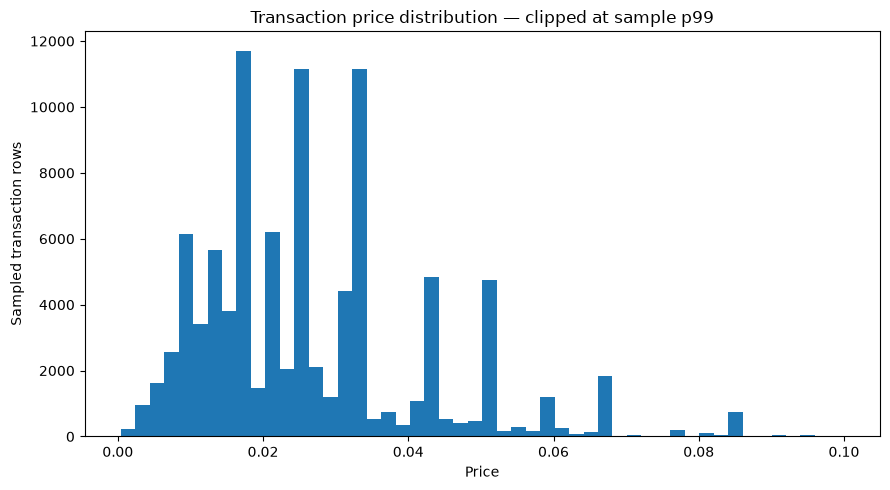

In [10]:
# Price visualization trên sample, không dùng toàn bộ 31.8M rows.
if len(price_sample):
    q = np.quantile(price_sample, [0, .01, .05, .25, .5, .75, .95, .99, 1])
    price_quantiles = pd.DataFrame({
        "quantile": ["min", "p01", "p05", "p25", "p50", "p75", "p95", "p99", "max"],
        "price": q
    })
    display(price_quantiles)
    price_quantiles.to_csv(TABLE_DIR / "10_price_sample_quantiles.csv", index=False)

    upper = np.quantile(price_sample, .99)
    clipped = price_sample[price_sample <= upper]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(clipped, bins=50)
    ax.set_xlabel("Price")
    ax.set_ylabel("Sampled transaction rows")
    ax.set_title("Transaction price distribution — clipped at sample p99")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "04_price_distribution_p99.png", dpi=160, bbox_inches="tight")
    plt.show()

## 5. Repeat-purchase feasibility — audit cấp customer

Đây là bước quan trọng để xem H&M có đủ hành vi lặp lại cho Extended RFM hay không.

Cell đầu tiên kiểm tra **transaction rows/customer**.  
Cell tiếp theo (khuyến nghị) dùng DuckDB để tính **distinct purchase days/customer** chính xác mà không cần load 31.8M dòng vào RAM.

Ta sẽ dùng `distinct purchase days` như một candidate definition cho `Frequency`, vì dataset không có `order_id`.

,value
count,1.362281e+06
mean,2.333463e+01
std,3.924225e+01
min,1.000000e+00
25%,3.000000e+00
50%,9.000000e+00
75%,2.700000e+01
90%,6.000000e+01
95%,9.100000e+01
99%,1.870000e+02


,metric,value
0,customers_with_1_transaction_row,1.315140e+05
1,customers_with_2plus_transaction_rows,1.230767e+06
2,pct_customers_with_2plus_transaction_rows,9.034604e+01


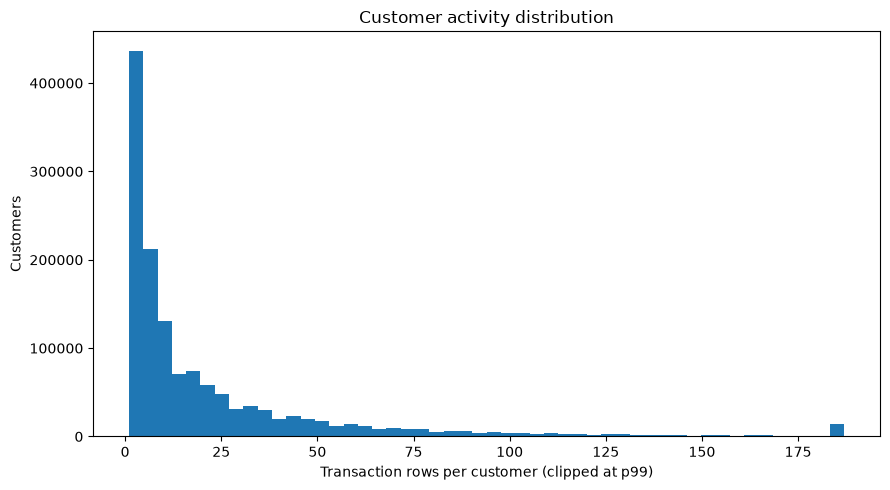

In [11]:
customer_line_series = pd.Series(customer_line_counts, name="transaction_rows")
customer_line_summary = customer_line_series.describe(
    percentiles=[.25, .5, .75, .9, .95, .99]
).to_frame("value")

display(customer_line_summary)
customer_line_summary.to_csv(TABLE_DIR / "11_customer_transaction_rows_summary.csv")

repeat_line_stats = pd.DataFrame({
    "metric": [
        "customers_with_1_transaction_row",
        "customers_with_2plus_transaction_rows",
        "pct_customers_with_2plus_transaction_rows"
    ],
    "value": [
        int((customer_line_series == 1).sum()),
        int((customer_line_series >= 2).sum()),
        float((customer_line_series >= 2).mean() * 100)
    ]
})
display(repeat_line_stats)
repeat_line_stats.to_csv(TABLE_DIR / "12_repeat_transaction_row_stats.csv", index=False)

plot_counts = customer_line_series.clip(upper=customer_line_series.quantile(.99))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(plot_counts, bins=50)
ax.set_xlabel("Transaction rows per customer (clipped at p99)")
ax.set_ylabel("Customers")
ax.set_title("Customer activity distribution")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_transaction_rows_per_customer.png", dpi=160, bbox_inches="tight")
plt.show()

,customer_id,purchase_days,first_purchase_date,last_purchase_date
0,ab5685305edf2c2ac552f3693ecf92bf5584e6322cc338...,22,2018-09-24,2020-06-30
1,abdcf0744eb2c85ff8a9f3fc009f44d8ebf4bc84424be8...,13,2018-09-29,2020-09-11
2,b0e6f40c45f51bc4f29efd31b71e2e88e5d183d99e8af3...,10,2018-09-29,2020-08-13
3,b0ebac38e325b2eae3613ea2a37b1a5513c8466b0ac386...,20,2018-09-29,2020-09-02
4,b14c7d17b9803618c2085f26a33f28f1ddc411612d169e...,11,2018-09-29,2020-06-15


count    1.362281e+06
mean     6.665423e+00
std      9.707005e+00
min      1.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      8.000000e+00
90%      1.700000e+01
95%      2.400000e+01
99%      4.500000e+01
max      4.270000e+02
Name: purchase_days, dtype: float64

,metric,value
0,customers,1.362281e+06
1,customers_with_2plus_purchase_days,9.143080e+05
2,pct_with_2plus_purchase_days,6.711596e+01
3,customers_with_3plus_purchase_days,7.311920e+05
4,pct_with_3plus_purchase_days,5.367410e+01


Estimated T coverage (>=2 purchase days): 67.12%
Estimated regularity coverage (>=3 purchase days): 53.67%


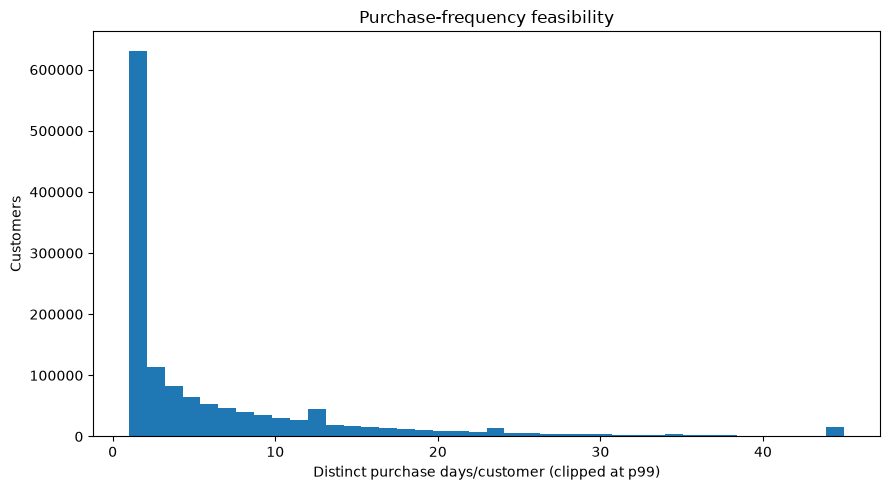

In [12]:
# OPTIONAL BUT RECOMMENDED:
# Exact audit of distinct purchase days with DuckDB.
# Nếu chưa có DuckDB, chạy: %pip install duckdb

try:
    import duckdb

    con = duckdb.connect()

    purchase_days = con.execute(f'''
        SELECT
            customer_id,
            COUNT(DISTINCT t_dat) AS purchase_days,
            MIN(CAST(t_dat AS DATE)) AS first_purchase_date,
            MAX(CAST(t_dat AS DATE)) AS last_purchase_date
        FROM read_csv_auto('{TRANSACTIONS_PATH.as_posix()}')
        GROUP BY customer_id
    ''').df()

    display(purchase_days.head())
    display(
        purchase_days["purchase_days"].describe(
            percentiles=[.25, .5, .75, .9, .95, .99]
        )
    )

    purchase_day_stats = pd.DataFrame({
        "metric": [
            "customers",
            "customers_with_2plus_purchase_days",
            "pct_with_2plus_purchase_days",
            "customers_with_3plus_purchase_days",
            "pct_with_3plus_purchase_days"
        ],
        "value": [
            len(purchase_days),
            int((purchase_days["purchase_days"] >= 2).sum()),
            float((purchase_days["purchase_days"] >= 2).mean() * 100),
            int((purchase_days["purchase_days"] >= 3).sum()),
            float((purchase_days["purchase_days"] >= 3).mean() * 100)
        ]
    })

    display(purchase_day_stats)
    purchase_day_stats.to_csv(
        TABLE_DIR / "13_purchase_day_feasibility.csv",
        index=False
    )

    # Coverage cho Interpurchase Time:
    # cần >= 2 distinct purchase dates.
    t_coverage = (purchase_days["purchase_days"] >= 2).mean() * 100
    regularity_coverage = (purchase_days["purchase_days"] >= 3).mean() * 100

    print(f"Estimated T coverage (>=2 purchase days): {t_coverage:.2f}%")
    print(f"Estimated regularity coverage (>=3 purchase days): {regularity_coverage:.2f}%")

    clipped_days = purchase_days["purchase_days"].clip(
        upper=purchase_days["purchase_days"].quantile(.99)
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(clipped_days, bins=40)
    ax.set_xlabel("Distinct purchase days/customer (clipped at p99)")
    ax.set_ylabel("Customers")
    ax.set_title("Purchase-frequency feasibility")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "06_distinct_purchase_days.png", dpi=160, bbox_inches="tight")
    plt.show()

except ImportError:
    print(
        "DuckDB chưa được cài. Đây không phải lỗi của dữ liệu. "
        "Cài bằng `%pip install duckdb` rồi chạy lại cell này để có exact distinct-purchase-day audit."
    )

## 6. Candidate Feature Feasibility Table

Bảng này **không chọn feature cuối**. Nó chỉ trả lời:

> “Từ H&M, feature này có thể tạo một cách hợp lệ hay không?”

Các feature `CVR`, `CancelRate`, `ReturnRate`, `AOV theo order` được đánh dấu không khả dụng vì raw data không chứa view/cart/order-status/return/order-id tương ứng.

In [13]:
feature_feasibility = pd.DataFrame([
    ["Recency (R)", "transactions: t_dat, customer_id", True, "RFM core", "Days since last purchase relative to snapshot date"],
    ["Frequency — distinct purchase days (F_day)", "transactions: t_dat, customer_id", True, "RFM core", "Candidate frequency definition because no order_id"],
    ["Item Frequency", "transactions: customer_id", True, "Behavior", "Number of transaction rows/items; not number of orders"],
    ["Monetary (M)", "transactions: price", True, "RFM core", "Sum of observed purchase price"],
    ["Mean Interpurchase Time (T)", "t_dat + customer_id", True, "Temporal", "Valid only for customers with >=2 purchase days"],
    ["Purchase Regularity", "t_dat + customer_id", True, "Temporal", "Std/dispersion of intervals; meaningful with repeated purchase days"],
    ["Avg Item Price", "price + customer_id", True, "Spending", "Mean purchased item price"],
    ["Avg Spend per Purchase Day", "price + t_dat + customer_id", True, "Spending", "Safer than AOV because there is no order_id"],
    ["Product Diversity", "article_id + customer_id", True, "Fashion diversity", "Distinct articles purchased"],
    ["Product Type Diversity", "transactions + articles.product_type", True, "Fashion diversity", "Distinct product types purchased"],
    ["Garment Group Diversity", "transactions + articles.garment_group", True, "Fashion diversity", "Distinct garment groups purchased"],
    ["Colour Diversity", "transactions + articles.colour_group", True, "Fashion diversity", "Distinct colour groups purchased"],
    ["Sales Channel Preference", "sales_channel_id", True, "Channel", "Share/primary channel; do not rename channels without verified mapping"],
    ["Age", "customers.age", True, "Customer metadata", "Use only after quality/ethics/utility analysis"],
    ["Club Member Status", "customers.club_member_status", True, "Customer metadata", "Candidate profiling or model feature"],
    ["Fashion News Frequency", "customers.fashion_news_frequency", True, "Customer metadata", "Candidate engagement/profile feature"],
    ["AOV (true order value)", "requires order_id", False, "Not available", "Dataset has no order_id"],
    ["CVR view→purchase", "requires view events", False, "Not available", "Dataset contains purchase history, not page views"],
    ["Cancel Rate", "requires cancellation/order status", False, "Not available", "No cancellation flag/status in transaction table"],
    ["Return Rate", "requires returns", False, "Not available", "No return event/status in supplied transaction table"],
], columns=[
    "feature",
    "raw_dependencies",
    "can_compute",
    "feature_group",
    "reason_or_limitation"
])

display(feature_feasibility)
feature_feasibility.to_csv(
    TABLE_DIR / "14_candidate_feature_feasibility.csv",
    index=False
)

,feature,raw_dependencies,can_compute,feature_group,reason_or_limitation
0,Recency (R),"transactions: t_dat, customer_id",True,RFM core,Days since last purchase relative to snapshot ...
1,Frequency — distinct purchase days (F_day),"transactions: t_dat, customer_id",True,RFM core,Candidate frequency definition because no orde...
2,Item Frequency,transactions: customer_id,True,Behavior,Number of transaction rows/items; not number o...
3,Monetary (M),transactions: price,True,RFM core,Sum of observed purchase price
4,Mean Interpurchase Time (T),t_dat + customer_id,True,Temporal,Valid only for customers with >=2 purchase days
5,Purchase Regularity,t_dat + customer_id,True,Temporal,Std/dispersion of intervals; meaningful with r...
6,Avg Item Price,price + customer_id,True,Spending,Mean purchased item price
7,Avg Spend per Purchase Day,price + t_dat + customer_id,True,Spending,Safer than AOV because there is no order_id
8,Product Diversity,article_id + customer_id,True,Fashion diversity,Distinct articles purchased
9,Product Type Diversity,transactions + articles.product_type,True,Fashion diversity,Distinct product types purchased


## 7. Phase 1 — Evidence checklist

Sau khi chạy notebook, **chưa được chuyển sang cleaning** nếu chưa trả lời được:

- [ ] Khoảng thời gian chính xác của transaction data là gì?
- [ ] Customer coverage giữa `transactions` và `customers` có khớp không?
- [ ] Article coverage giữa `transactions` và `articles` có khớp không?
- [ ] Missing nghiêm trọng nằm ở cột nào?
- [ ] `customer_id`/`article_id` metadata có duplicate key không?
- [ ] Bao nhiêu % khách có >= 2 distinct purchase days?
- [ ] Bao nhiêu % có >= 3 distinct purchase days?
- [ ] Coverage của `T` và `PurchaseRegularity` có đủ không?
- [ ] Metadata fashion nào có coverage/cardinality phù hợp?
- [ ] Candidate feature nào chắc chắn không thể tạo?

In [14]:
# Kiểm tra referential coverage giữa transaction sample và metadata.
# Đây là kiểm tra sample nhanh; full coverage có thể làm bằng DuckDB ở Phase 1 nếu cần.

customer_ids_master = set(customers["customer_id"].astype("string").dropna())
article_ids_master = set(articles["article_id"].astype("string").dropna())

sample_customer_coverage = transactions_sample["customer_id"].isin(customer_ids_master).mean() * 100
sample_article_coverage = transactions_sample["article_id"].astype("string").isin(article_ids_master).mean() * 100

coverage_table = pd.DataFrame({
    "check": [
        "transaction sample customer_id found in customers",
        "transaction sample article_id found in articles"
    ],
    "coverage_pct": [
        sample_customer_coverage,
        sample_article_coverage
    ]
})

display(coverage_table)
coverage_table.to_csv(TABLE_DIR / "15_sample_referential_coverage.csv", index=False)

,check,coverage_pct
0,transaction sample customer_id found in customers,100.0
1,transaction sample article_id found in articles,100.0


## 8. Kết luận Phase 1 — điền sau khi chạy

Sau khi có output thật, phần Markdown cuối này sẽ được viết lại thành kết luận dùng trực tiếp cho báo cáo.

Template:

> Dataset H&M gồm ... customer, ... article và ... transaction rows trong khoảng ... đến ....  
> Các bảng metadata cho thấy ....  
> Phân tích hành vi mua lặp lại cho thấy ...% customer có từ hai purchase days trở lên, vì vậy `Interpurchase Time` [có/không] đủ coverage để đưa vào candidate pool.  
> Các thuộc tính thời trang có coverage tốt gồm ....  
> Các feature không thể tạo hợp lệ từ dataset gồm CVR, CancelRate, ReturnRate và true AOV vì ....  
> Do đó, candidate feature pool chuyển sang Phase 2 gồm ....

**Không tự điền con số trước khi chạy dữ liệu thật.**